In [ ]:
import pandas as pd                      # for working with tables
import numpy as np                       # for numbers and random values
import matplotlib.pyplot as plt          # for charts

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

print("Ready.")

Ready.


In [ ]:
column_names = [
    "duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes",
    "land", "wrong_fragment", "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login",
    "is_guest_login", "count", "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate", "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "label", "difficulty",
]

url = "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"
data = pd.read_csv(url, header=None, names=column_names)

print("Number of rows:", len(data))
print("Number of columns:", len(data.columns))
data.head(3)

Number of rows: 125973
Number of columns: 43


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.0,0.0,0.0,0.05,0.0,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.0,0.0,0.0,0.00,0.0,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.0,1.0,1.0,0.00,0.0,neptune,19


In [ ]:
data["attack"] = (data["label"] != "normal").astype(int)

print(data["attack"].value_counts())
print()
print("0 = normal, 1 = suspicious")

attack
0    67343
1    58630
Name: count, dtype: int64

0 = normal, 1 = suspicious


In [ ]:
feature_names = [
    "duration", "src_bytes", "dst_bytes", "count",
    "srv_count", "serror_rate", "same_srv_rate", "dst_host_srv_count",
]

X = data[feature_names]
y = data["attack"]

X.describe()

,duration,src_bytes,dst_bytes,count,srv_count,serror_rate,same_srv_rate,dst_host_srv_count
count,125973.00000,1.259730e+05,1.259730e+05,125973.000000,125973.000000,125973.000000,125973.000000,125973.000000
mean,287.14465,4.556674e+04,1.977911e+04,84.107555,27.737888,0.284485,0.660928,115.653005
std,2604.51531,5.870331e+06,4.021269e+06,114.508607,72.635840,0.446456,0.439623,110.702741
min,0.00000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.00000,0.000000e+00,0.000000e+00,2.000000,2.000000,0.000000,0.090000,10.000000
50%,0.00000,4.400000e+01,0.000000e+00,14.000000,8.000000,0.000000,1.000000,63.000000
75%,0.00000,2.760000e+02,5.160000e+02,143.000000,18.000000,1.000000,1.000000,255.000000
max,42908.00000,1.379964e+09,1.309937e+09,511.000000,511.000000,1.000000,1.000000,255.000000


In [ ]:
sample = data.sample(n=6000, random_state=42)

X_sample = sample[feature_names]
y_sample = sample["attack"]

X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample, test_size=0.2, random_state=42, stratify=y_sample
)

print("Training rows:", len(X_train))
print("Testing rows :", len(X_test))

Training rows: 4800
Testing rows : 1200


In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)   # learn AND apply on training data
X_test_scaled = scaler.transform(X_test)          # only apply on test data

print("Before scaling (first row):", X_train.iloc[0].values)
print("After scaling  (first row):", np.round(X_train_scaled[0], 3))

Before scaling (first row): [  0.     0.     0.   132.    20.     0.     0.15  20.  ]
After scaling  (first row): [-0.125 -0.039 -0.133  0.413 -0.117 -0.645 -1.141 -0.851]


In [ ]:
model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
model.fit(X_train_scaled, y_train)

print("Model trained.")
print("Number of support vectors (points that shape the boundary):", model.support_vectors_.shape[0])

Model trained.
Number of support vectors (points that shape the boundary): 1042


In [ ]:
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy on the test set:", round(accuracy, 4), "  that is about", round(accuracy * 100, 1), "%")

Accuracy on the test set: 0.9192   that is about 91.9 %


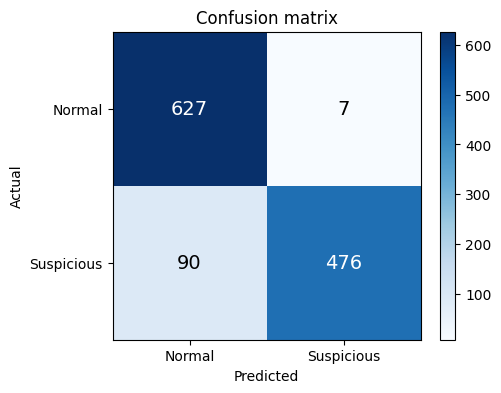

              precision    recall  f1-score   support

      Normal       0.87      0.99      0.93       634
  Suspicious       0.99      0.84      0.91       566

    accuracy                           0.92      1200
   macro avg       0.93      0.91      0.92      1200
weighted avg       0.93      0.92      0.92      1200



In [ ]:
cm = confusion_matrix(y_test, y_pred)

labels = ["Normal", "Suspicious"]
plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap="Blues")
plt.xticks([0, 1], labels)
plt.yticks([0, 1], labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix")

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                  color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)

plt.colorbar()
plt.show()

print(classification_report(y_test, y_pred, target_names=labels))

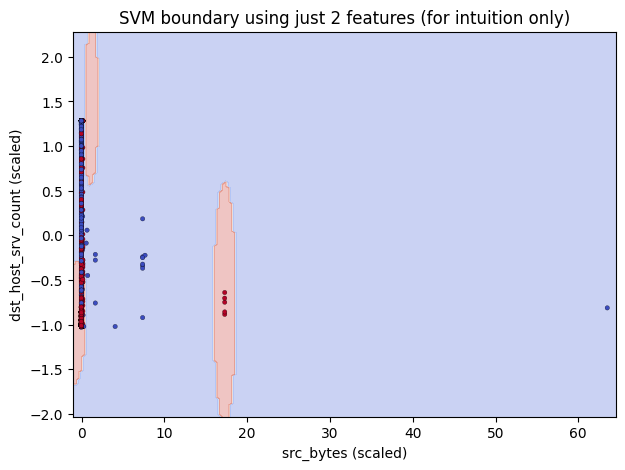

Blue-ish region = predicted normal, red-ish region = predicted suspicious.


In [ ]:
two_features = ["src_bytes", "dst_host_srv_count"]
scaler_demo = StandardScaler()
X2 = scaler_demo.fit_transform(sample[two_features])
y2 = sample["attack"].to_numpy()

demo_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)
demo_model.fit(X2, y2)

x_min, x_max = X2[:, 0].min() - 1, X2[:, 0].max() + 1
y_min, y_max = X2[:, 1].min() - 1, X2[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
zz = demo_model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7, 5))
plt.contourf(xx, yy, zz, alpha=0.3, cmap="coolwarm")
plt.scatter(X2[:, 0], X2[:, 1], c=y2, cmap="coolwarm", s=10, edgecolors="k", linewidths=0.2)
plt.xlabel("src_bytes (scaled)")
plt.ylabel("dst_host_srv_count (scaled)")
plt.title("SVM boundary using just 2 features (for intuition only)")
plt.show()

print("Blue-ish region = predicted normal, red-ish region = predicted suspicious.")

In [ ]:
def check_connection(duration=0, src_bytes=0, dst_bytes=0, count=1,
                      srv_count=1, serror_rate=0.0, same_srv_rate=1.0,
                      dst_host_srv_count=1):
    row = pd.DataFrame([{
        "duration": duration, "src_bytes": src_bytes, "dst_bytes": dst_bytes,
        "count": count, "srv_count": srv_count, "serror_rate": serror_rate,
        "same_srv_rate": same_srv_rate, "dst_host_srv_count": dst_host_srv_count,
    }])[feature_names]

    prediction = model.predict(scaler.transform(row))[0]

    if prediction == 1:
        print("Prediction: SUSPICIOUS — this looks like an attack.")
    else:
        print("Prediction: NORMAL — this looks like ordinary traffic.")


print("EXAMPLE 1 - short, quiet connection")
check_connection(duration=2, src_bytes=200, dst_bytes=300, count=2, srv_count=2,
                  serror_rate=0.0, same_srv_rate=1.0, dst_host_srv_count=5)

print()
print("EXAMPLE 2 - many connections in 2 seconds, lots of SYN errors")
check_connection(duration=0, src_bytes=0, dst_bytes=0, count=200, srv_count=180,
                  serror_rate=0.95, same_srv_rate=0.1, dst_host_srv_count=255)

EXAMPLE 1 - short, quiet connection
Prediction: NORMAL — this looks like ordinary traffic.

EXAMPLE 2 - many connections in 2 seconds, lots of SYN errors
Prediction: NORMAL — this looks like ordinary traffic.


In [ ]:
check_connection(duration=0,
                  src_bytes=1200,
                  dst_bytes=50,
                  count=15,
                  srv_count=12,
                  serror_rate=0.4,
                  same_srv_rate=0.6,
                  dst_host_srv_count=100)

Prediction: NORMAL — this looks like ordinary traffic.


In [ ]:
results = X_test.copy()
results["actual"] = y_test.values
results["predicted"] = y_pred
results.to_csv("unit2_svm_predictions.csv", index=False)

report_table = pd.DataFrame(classification_report(y_test, y_pred, target_names=labels, output_dict=True)).transpose()
report_table.to_csv("unit2_svm_report.csv")

print("Saved: unit2_svm_predictions.csv")
print("Saved: unit2_svm_report.csv")

Saved: unit2_svm_predictions.csv
Saved: unit2_svm_report.csv


## What we found

1. Using just 8 real traffic-flow features, the SVM correctly classifies the large majority of test connections as normal or suspicious.
2. Scaling the features before training matters a lot for SVMs, because they rely on distance between points.
3. The confusion matrix matters more than accuracy alone — in intrusion detection, a missed attack (**False Normal**) is far more costly than a false alarm (**False Suspicious**).
4. The 2-feature plot shows the SVM does not draw a straight line — it curves the boundary to fit the shape of the data (the RBF kernel).
5. This is the same NSL-KDD dataset from Unit 1, but instead of counting rows we let an algorithm learn the boundary itself.

## Reference

Dataset: NSL-KDD, Canadian Institute for Cybersecurity — https://www.unb.ca/cic/datasets/nsl.html